**Aim:** Identify cell types – cluster annotation 

**Tools**: 
- [`scanpy`](https://scanpy.readthedocs.io/en/stable/)

In [1]:
import os, sys
import pickle
import numpy as np 
import pandas as pd
from glob import glob

import scanpy as sc
import scanpy.external as sce
import anndata as ad
import scvi

import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import pyplot as plot
from matplotlib.backends.backend_pdf import PdfPages

sc.settings.verbosity = 1             # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.set_figure_params(dpi=300,dpi_save=300, frameon=False, figsize=(5, 5), facecolor='white')

sc.logging.print_header()

scanpy==1.9.1 anndata==0.7.6 umap==0.5.1 numpy==1.20.3 scipy==1.7.1 pandas==1.3.3 scikit-learn==1.0 statsmodels==0.13.0 python-igraph==0.9.8 pynndescent==0.5.4


In [2]:
# https://stackoverflow.com/questions/21884271/warning-about-too-many-open-figures
plt.rcParams.update({'figure.max_open_warning': 0})

plt.close('all')

In [3]:
# https://stackoverflow.com/questions/3899980/how-to-change-the-font-size-on-a-matplotlib-plot

SMALL_SIZE = 6
MEDIUM_SIZE = 8
BIGGER_SIZE = 10

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=SMALL_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title


In [4]:
from utils import *

Load filtered, normalized, and clustered `adata` files for all three conditions: 

In [95]:
Snap25_pos  = sc.read_h5ad('celltyping/Snap25_pos.h5ad.gz')
Snap25_neg  = sc.read_h5ad('celltyping/Snap25_neg.h5ad.gz')

Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.


In [96]:
Snap25_neg.var_names_make_unique()

## Cluster and then annotate neuronal/non-neuronal cells
Ting's comments: 

In [97]:
cell_types = {
    "non-neuronal cells":[
        "Endothelial","Oligodentrocyte",
        "OPCs", # oligodendrocyte progenitor cells 
        "Microglia","interneuron","astrocytes","neuroblast"
    ],

    "neuron":[
        "neuron main markers",
        "GABAergic",
        "glutamatergic",
        "D1 MSN",
        "D2 MSN (Ppp1r1b+ medial spiny neuron)",
        "D1H",
        "ICj"
    ]
}

marker_genes = {
    "OPCs":['Pdgfra'], # oligodendrocyte progenitor cells
    "interneuron":["Resp18",'Lhx6','Zic1'],
    "Endothelial": ["Cldn5","Ptprb"], #"Ptgds"
    "Oligodentrocyte":["Mog",'Opalin'], # "Olig1",
    "Microglia":['C1qb','C1qa'], #"Cx3cr1",
    "astrocytes":["Aqp4",'Slc1a3','Gja1'],
    "neuroblast":["Top2a"],
    "neuron main markers":['Snap25','Zic2',#"Gria2", "Penk",'Dck','Nrxn1',"Nfasc","Kctd13",
                           "Sox11" #"Aplp1","Syt11","Slc2a1","Slc1a2","Slc4a4","Slc6a6","Qpct"
                          ],
    "GABAergic":["Gad1"],
    "glutamatergic":[
        "Slc17a7",
        "Gria1",
        "Gria2",
        "Grin1",
        "Grin3a",
        "Lrrtm2",
        "Slc1a1",
        "Slc1a2",
        "Slc6a13",
        "Slc7a11",
        "Slc17a6",
        "Slc17a6",
    ],
    "D1 MSN":['Tac1',"Pdyn"], # ,"Drd1a"
    "D2 MSN (Ppp1r1b+ medial spiny neuron)":["Penk","Drd2","Adora2a"],
    "D1H":["Nxph4","Tac2"],
    "ICj":["Crtac1","Rreb1"],
    "patch marker":["Sema5b"],
    "ventral striatum marker":["Crym"],
    "medial Shell":["Stard5","Stra6"]
}

In [98]:
neuron_genes = {
    cell_type: marker_genes[cell_type] 
    # gene 
    for cell_type in marker_genes 
    # for gene in marker_genes[cell_type] 
    if cell_type in cell_types['neuron']
}

not_neuron_genes = {
    cell_type: marker_genes[cell_type] 
    # gene 
    for cell_type in marker_genes 
    # for gene in marker_genes[cell_type] 
    if cell_type not in cell_types['neuron']
}

### Snap25- cells


In [102]:
leiden_list = []
for l in Snap25_neg.obs.leiden:
    if int(l) in [8, 10, 15]: leiden_list.append('Microglia')
    elif int(l) in [7,0,1,3,6]: leiden_list.append('Endothelial')
    elif int(l) in [2, 4, 18,19]: leiden_list.append('Oligodendrocytes')
    elif int(l) in [16]: leiden_list.append('Astrocytes')
    elif int(l) in [17]: leiden_list.append('interneuron')
    elif int(l) in [14]: leiden_list.append('neuroblast')
    elif int(l) in [5,11,12,9]: leiden_list.append('OPCs')
    else: leiden_list.append(l)
# len (leiden_list) == len(Snap25_neg.obs.leiden)

Snap25_neg.obs['label'] = pd.Categorical(leiden_list)

In [103]:
sc.tl.dendrogram(Snap25_neg,'label')

categories: 13, Astrocytes, Endothelial, etc.
var_group_labels: OPCs, interneuron, Endothelial, etc.


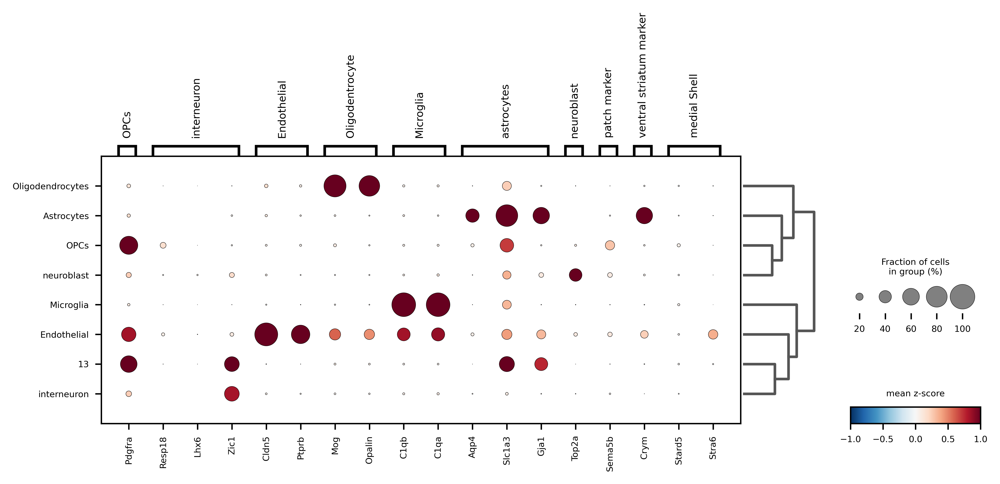

‘figures/dotplot_Snap25_neg.pdf’ -> ‘celltyping/Snap25_neg_dotplot.pdf’


In [104]:
ax = sc.pl.dotplot(
    Snap25_neg, 
    not_neuron_genes, 
    groupby=['label'], swap_axes=False, dendrogram=True,
    colorbar_title='mean z-score', 
    # layer='scaled', 
    vmin=-1, vmax=1, cmap='RdBu_r',
    save = 'Snap25_neg'
)

!mv -v figures/dotplot_Snap25_neg.pdf celltyping/Snap25_neg_dotplot.pdf

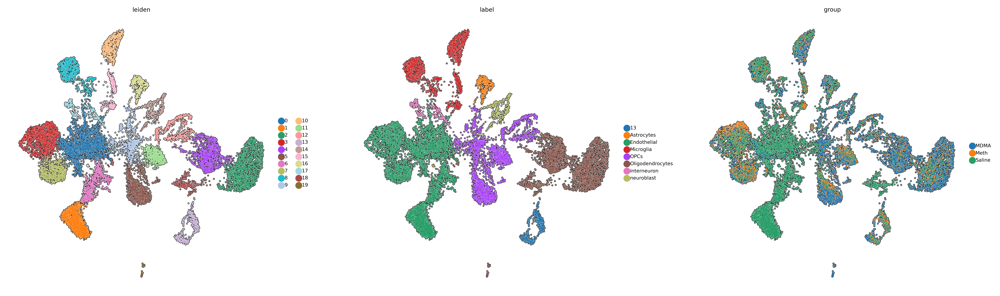

In [105]:
sc.pl.umap(
    Snap25_neg, 
    color=['leiden','label','group'],
    legend_fontsize='small',
    size=5, hspace=2, alpha=0.7,
    save='Snap25_neg.pdf',
    add_outline=1
)

!mv figures/umapSnap25_neg.pdf celltyping/Snap25_neg_umap.pdf

In [106]:
Snap25_neg.write(
    'celltyping/Snap25_neg-annotated.h5ad.gz',
    compression='gzip'
)

## Snap25 +

In [121]:
sc.pp.scale(Snap25_pos, max_value=10)

Snap25_pos.layers["scaled"] = Snap25_pos.X.copy()

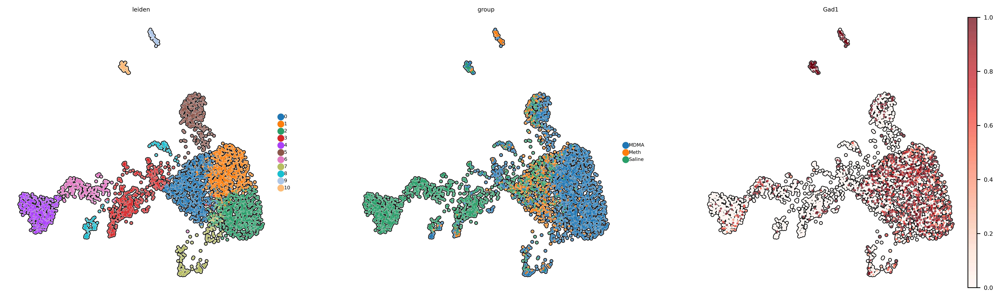

In [128]:
sc.pl.umap(
    Snap25_pos, 
    color=['leiden',
           'group',
           # - label GAD1 (GABAergic marker) on UMAP 
           'Gad1',
          ],
    legend_fontsize='small',
    size=20, hspace=2, alpha=0.7,
    vmin=0,
    vmax=1,
    cmap='Reds', 
    layer='scaled',

    save='Snap25_pos.pdf',
    add_outline=0.1
)

!mv figures/umapSnap25_pos.pdf celltyping/Snap25_pos_umap.pdf

## Label all cells 

In [107]:
results_file = 'celltyping/adata-norm-umap.gz'

adata  = sc.read_h5ad(results_file)

Variable names are not unique. To make them unique, call `.var_names_make_unique`.


In [108]:
Snap25_neg  = sc.read_h5ad('celltyping/Snap25_neg-annotated.h5ad.gz')

In [109]:
adata.obs['label'] = 'Neuron'

In [110]:
adata.obs.loc[
    Snap25_neg.obs.index, 'label'
] = Snap25_neg.obs.label.tolist()

In [111]:
set(adata.obs.label)

{'13',
 'Astrocytes',
 'Endothelial',
 'Microglia',
 'Neuron',
 'OPCs',
 'Oligodendrocytes',
 'interneuron',
 'neuroblast'}

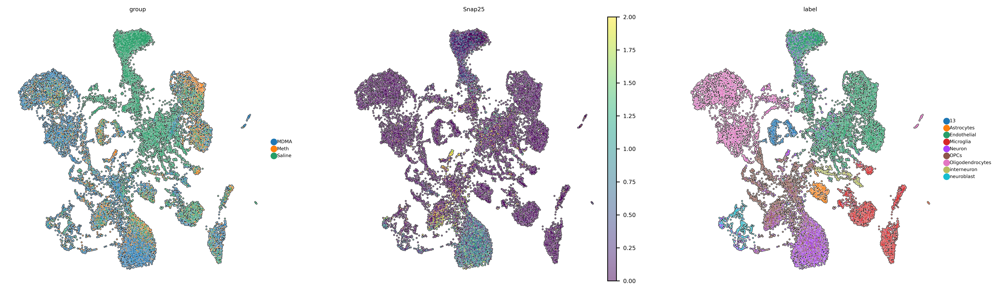

In [114]:
sc.pl.umap(
    adata, 
    color=['group','Snap25','label'],
    legend_fontsize='small',
    size=5, hspace=2, alpha=0.5,
    vmax=2,
    save='All.pdf',
    add_outline=1
)

!mv figures/umapAll.pdf celltyping/All_umap.pdf

In [113]:
!date

Wed Aug 10 18:22:34 PDT 2022
